# 09 · An End-to-End ML Project — Customer Churn

Notebooks 01–08 taught the pieces. This notebook puts them together the way a real project runs, from a business question to a saved model someone can use.

**The scenario.** A subscription company loses ~28% of customers. The retention team can contact a limited number of customers each month and offer them a discount. **Which customers should they contact?**

**The steps**
1. Frame the problem: what to predict, how success is measured **in money**, not just accuracy
2. Split the data and lock away a test set
3. Build **baselines** first
4. Preprocessing pipelines for different model families
5. Compare models fairly with cross-validation
6. **Tune hyperparameters:** 🐍 hand-written random search → 📦 scikit-learn `RandomizedSearchCV` → 📦 **Optuna** (Bayesian optimisation)
7. Error analysis and **calibration** (can we trust the probabilities?)
8. Choose a **decision threshold from business costs**
9. Final, one-time test evaluation with a **confidence interval**
10. **Save** the model, reload it, and predict for a new customer
11. What to monitor after launch

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time, warnings
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

from churn_utils import load_clean, CATEGORICAL, TARGET
df, X, y = load_clean()          # raw CSV → cleaned + engineered features (developed in notebook 08)
print(X.shape, f"churn rate {y.mean():.1%}")
X.head(3)

(6000, 17) churn rate 27.8%


,age,region,plan,contract,payment_method,has_partner,monthly_charges,tenure_months,total_charges,support_calls,avg_session_minutes,satisfaction_score,last_login_days_ago,charges_per_month_of_tenure,is_new_customer,satisfaction_missing,log_last_login
0,49.0,west,standard,month-to-month,electronic check,no,64.19,31,1986.03,0,24.4,NaN,0,62.063437,0,1,0.000000
1,NaN,west,standard,two-year,credit card,no,50.54,41,2069.93,0,18.7,3.0,17,49.284048,0,0,2.890372
2,50.0,north,basic,two-year,credit card,no,38.16,40,1519.48,2,20.5,3.0,16,37.060488,0,0,2.833213


## 1. Frame the problem

Before touching a model, pin down three things with the people who will use it:

| Question | Answer for this project |
|---|---|
| **What exactly do we predict?** | probability a customer cancels in the next period (`churned`) |
| **What action follows?** | the retention team calls the customer and offers a discount |
| **What does a mistake cost?** | see below |

**Assumed business numbers** (in a real project, you get these from the finance/retention teams):
- Contacting a customer + discount costs **$30**.
- A customer we keep is worth **$300** in future revenue.
- If we contact someone who *would* churn, the offer saves them **40%** of the time.

So contacting a true churner gains on average 0.4 × $300 − $30 = **+$90**; contacting a loyal customer wastes **−$30**. Doing nothing costs nothing (relative to today).

**Metrics.** For *ranking* customers by risk: **ROC-AUC** and **PR-AUC** (notebook 03). For the *decision*: **expected profit**. Accuracy is not useful here — the classes are imbalanced and the two kinds of mistake cost very different amounts.

In [2]:
GAIN_TP = 0.4 * 300 - 30     # contacted, would have churned
COST_FP = -30                # contacted, would have stayed anyway

def profit(y_true, contact):
    """Expected $ from contacting the customers flagged in `contact` (a 0/1 array)."""
    y_true, contact = np.asarray(y_true), np.asarray(contact).astype(bool)
    return GAIN_TP * np.sum(contact & (y_true == 1)) + COST_FP * np.sum(contact & (y_true == 0))

## 2. Split — and lock away the test set

The test set is the stand-in for "the future". We'll touch it **once**, at the very end. All model choices are made with cross-validation on the training set.

(Our data is a single snapshot, so a stratified random split is fine. With timestamps — e.g. monthly snapshots — you'd train on earlier months and test on later ones.)

In [3]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
print(f"train {X_train.shape}, test {X_test.shape} — churn rate {y_train.mean():.3f} / {y_test.mean():.3f}")

train (4800, 17), test (1200, 17) — churn rate 0.278 / 0.278


## 3. Baselines first

A baseline tells you whether ML is worth it at all, and gives every later model something to beat.
1. **Do nothing** — contact no one.
2. **Contact everyone.**
3. **A simple human rule** — "contact every month-to-month customer".
4. **A simple model** — logistic regression.

In [4]:
n_train = len(y_train)
print(f"do nothing:              profit ${profit(y_train, np.zeros(n_train)):>9,.0f}")
print(f"contact everyone:        profit ${profit(y_train, np.ones(n_train)):>9,.0f}")
rule = (X_train["contract"] == "month-to-month").to_numpy()
print(f"rule (month-to-month):   profit ${profit(y_train, rule):>9,.0f}  (contacts {rule.sum()} customers)")
print("(profits on the 4,800 training customers — used only to compare against later, on the same customers)")

do nothing:              profit $        0
contact everyone:        profit $   16,080
rule (month-to-month):   profit $   48,180  (contacts 2666 customers)
(profits on the 4,800 training customers — used only to compare against later, on the same customers)


## 4. Preprocessing pipelines

Different model families want different preprocessing (notebook 08):
- **Linear models, SVM, KNN, neural nets:** impute → scale numbers; one-hot categories.
- **Tree ensembles:** no scaling; ordinal-coded categories are fine; histogram GBMs handle NaN themselves.

In [5]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

numeric = [c for c in X.columns if c not in CATEGORICAL]
linear_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
])
print("numeric features:", numeric)

numeric features: ['age', 'monthly_charges', 'tenure_months', 'total_charges', 'support_calls', 'avg_session_minutes', 'satisfaction_score', 'last_login_days_ago', 'charges_per_month_of_tenure', 'is_new_customer', 'satisfaction_missing', 'log_last_login']


## 5. Compare models fairly

Same folds, same metric, whole pipeline inside the CV loop. We look at the **mean and the spread** — a difference smaller than the spread isn't convincing.

logistic regression      AUC 0.8144 ± 0.0179   (1.1s)
KNN (k=50)               AUC 0.7622 ± 0.0155   (0.2s)


random forest            AUC 0.8003 ± 0.0194   (3.3s)


hist gradient boosting   AUC 0.7940 ± 0.0214   (0.6s)


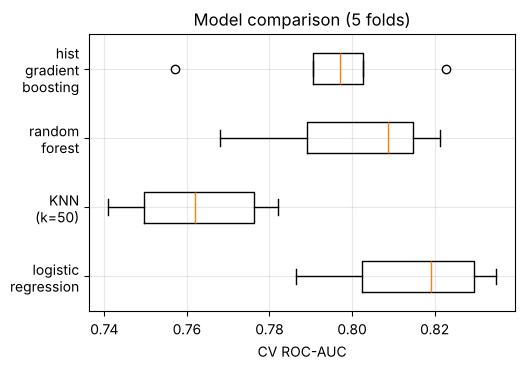

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

candidates = {
    "logistic regression": Pipeline([("prep", linear_prep), ("clf", LogisticRegression(max_iter=2000))]),
    "KNN (k=50)": Pipeline([("prep", linear_prep), ("clf", KNeighborsClassifier(50))]),
    "random forest": Pipeline([("prep", tree_prep), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0))]),
    "hist gradient boosting": Pipeline([("prep", tree_prep), ("clf", HistGradientBoostingClassifier(random_state=0))]),
}
results = {}
for name, pipe in candidates.items():
    t0 = time.perf_counter()
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    results[name] = s
    print(f"{name:24s} AUC {s.mean():.4f} ± {s.std():.4f}   ({time.perf_counter() - t0:.1f}s)")

plt.boxplot(list(results.values()), tick_labels=[k.replace(" ", "\n") for k in results], orientation="horizontal")
plt.xlabel("CV ROC-AUC"); plt.title("Model comparison (5 folds)"); plt.show()

Logistic regression and gradient boosting are close. Default settings aren't the end of the story, though — next we tune the two strongest families.

## 6. Hyperparameter tuning

Three approaches, from simplest to smartest:

| Method | Idea | Trade-off |
|---|---|---|
| **Grid search** | try every combination | explodes: 5 params × 5 values = 3,125 fits × 5 folds |
| **Random search** | sample combinations at random | finds good regions fast, because usually only a few hyperparameters really matter |
| **Bayesian optimisation** (Optuna) | build a model of "settings → score" from past trials; try the most promising next | fewest trials for a good result |

Search **learning rates and regularisation strengths on a log scale** (0.001, 0.01, 0.1…) — their effect is multiplicative.

### 6.1 🐍 Random search by hand

In [7]:
import random

def sample_params(rnd):
    return {
        "learning_rate": 10 ** rnd.uniform(-2.3, -0.5),       # log-uniform between ~0.005 and ~0.3
        "max_leaf_nodes": rnd.choice([7, 15, 31, 63]),
        "min_samples_leaf": rnd.choice([10, 20, 50, 100]),
        "l2_regularization": 10 ** rnd.uniform(-3, 1),
        "max_iter": rnd.choice([100, 200, 400]),
    }

def random_search_python(n_trials=12, seed=0):
    rnd = random.Random(seed); best_score, best_params, history = -1.0, None, []
    for t in range(n_trials):
        params = sample_params(rnd)
        pipe = Pipeline([("prep", tree_prep), ("clf", HistGradientBoostingClassifier(random_state=0, **params))])
        score = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean()
        history.append(score)
        if score > best_score:
            best_score, best_params = score, params
    return best_score, best_params, history

t0 = time.perf_counter()
best_score, best_params, hist_manual = random_search_python()
print(f"best CV AUC {best_score:.4f} in {time.perf_counter() - t0:.0f}s with", {k: round(v, 4) if isinstance(v, float) else v for k, v in best_params.items()})

best CV AUC 0.8098 in 15s with {'learning_rate': 0.0126, 'max_leaf_nodes': 15, 'min_samples_leaf': 100, 'l2_regularization': 0.0023, 'max_iter': 200}


### 6.2 📦 scikit-learn `RandomizedSearchCV`
Same idea, plus parallelism, refitting the best model on all training data, and a results table. Note the `clf__` prefix: it addresses the `clf` step inside the pipeline.

In [8]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform

search = RandomizedSearchCV(
    Pipeline([("prep", tree_prep), ("clf", HistGradientBoostingClassifier(random_state=0))]),
    param_distributions={
        "clf__learning_rate": loguniform(0.005, 0.3),
        "clf__max_leaf_nodes": [7, 15, 31, 63],
        "clf__min_samples_leaf": [10, 20, 50, 100],
        "clf__l2_regularization": loguniform(1e-3, 10),
        "clf__max_iter": [100, 200, 400],
    },
    n_iter=12, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=0,
).fit(X_train, y_train)
print(f"RandomizedSearchCV best CV AUC {search.best_score_:.4f}")
pd.DataFrame(search.cv_results_).sort_values("rank_test_score")[["mean_test_score", "std_test_score", "param_clf__learning_rate", "param_clf__max_leaf_nodes", "param_clf__min_samples_leaf"]].head()

RandomizedSearchCV best CV AUC 0.8082


,mean_test_score,std_test_score,param_clf__learning_rate,param_clf__max_leaf_nodes,param_clf__min_samples_leaf
9,0.808178,0.019203,0.024334,15,50
6,0.802121,0.022596,0.045134,63,50
1,0.798462,0.017178,0.016906,7,10
8,0.796842,0.016215,0.005400,15,50
7,0.795247,0.023160,0.014770,63,10


### 6.3 📦 Optuna — Bayesian optimisation
Optuna's default sampler (TPE) splits past trials into "good" and "bad" and samples new settings that look like the good ones. You write an **objective function** that returns a score; Optuna calls it repeatedly.

We'll also tune the logistic regression's regularisation strength `C`, so both finalists get a fair chance.

In [9]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective_gbm(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 4, 64, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 200, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 10, log=True),
        "max_iter": trial.suggest_int("max_iter", 50, 500, log=True),
    }
    pipe = Pipeline([("prep", tree_prep), ("clf", HistGradientBoostingClassifier(random_state=0, **params))])
    return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean()

def objective_lr(trial):
    C = trial.suggest_float("C", 1e-3, 10, log=True)
    pipe = Pipeline([("prep", linear_prep), ("clf", LogisticRegression(C=C, max_iter=2000))])
    return cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1).mean()

study_gbm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study_gbm.optimize(objective_gbm, n_trials=30)
study_lr = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
study_lr.optimize(objective_lr, n_trials=15)
print(f"Optuna GBM best CV AUC {study_gbm.best_value:.4f}  {study_gbm.best_params}")
print(f"Optuna LR  best CV AUC {study_lr.best_value:.4f}  {study_lr.best_params}")

Optuna GBM best CV AUC 0.8122  {'learning_rate': 0.06818876814387921, 'max_leaf_nodes': 4, 'min_samples_leaf': 189, 'l2_regularization': 0.1865651148946215, 'max_iter': 103}
Optuna LR  best CV AUC 0.8145  {'C': 1.1446066488079247}


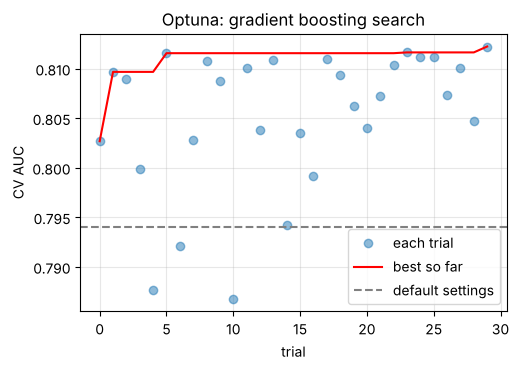

In [10]:
vals = [t.value for t in study_gbm.trials]
plt.plot(vals, "o", alpha=0.5, label="each trial"); plt.plot(np.maximum.accumulate(vals), "r-", label="best so far")
plt.axhline(results["hist gradient boosting"].mean(), ls="--", c="gray", label="default settings")
plt.xlabel("trial"); plt.ylabel("CV AUC"); plt.legend(); plt.title("Optuna: gradient boosting search"); plt.show()

**Pick the finalist.** Tuning lifted gradient boosting from its defaults, but tuned logistic regression is still level or slightly ahead. Gaps of a few thousandths of AUC are within noise (compare the fold spread), and when two models are this close you should prefer the **simpler, more explainable, cheaper** one. So the finalist is **logistic regression**.

Why does a linear model hold its own here? Notebook 08 engineered the key non-linear effects into features (new-customer flag, log of last login, missing-survey flag), and this dataset's churn process is mostly additive in log-odds — exactly the shape logistic regression assumes. On many real tabular datasets with more complex interactions, boosting wins clearly. **Always compare; never assume.**

In [11]:
best_gbm = Pipeline([("prep", tree_prep), ("clf", HistGradientBoostingClassifier(random_state=0, **study_gbm.best_params))])
best_lr = Pipeline([("prep", linear_prep), ("clf", LogisticRegression(C=study_lr.best_params["C"], max_iter=2000))])

# Out-of-fold predictions: every training row gets a prediction from a model that never saw it.
# We use these for error analysis, calibration and threshold choice — still without touching the test set.
oof = {name: cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
       for name, m in [("gbm", best_gbm), ("logreg", best_lr)]}
from sklearn.metrics import roc_auc_score, average_precision_score
for name, p in oof.items():
    print(f"{name:7s} OOF ROC-AUC {roc_auc_score(y_train, p):.4f}  PR-AUC {average_precision_score(y_train, p):.4f}")
final_model, p_oof = best_lr, oof["logreg"]

gbm     OOF ROC-AUC 0.8114  PR-AUC 0.6299
logreg  OOF ROC-AUC 0.8138  PR-AUC 0.6430


## 7. Error analysis & calibration

### 7.1 Where does the model struggle?
Slice performance by segment. Big gaps can reveal data problems, missing features, or fairness issues.

In [12]:
seg = X_train.assign(y=y_train, p=p_oof)
rows = []
for col in ["contract", "plan", "region", "is_new_customer"]:
    for val, g in seg.groupby(col):
        if g["y"].nunique() == 2:
            rows.append({"segment": f"{col} = {val}", "customers": len(g), "churn rate": g["y"].mean(), "AUC": roc_auc_score(g["y"], g["p"])})
pd.DataFrame(rows).round(3)

,segment,customers,churn rate,AUC
0,contract = month-to-month,2666,0.401,0.752
1,contract = one-year,1201,0.169,0.756
2,contract = two-year,933,0.068,0.823
3,plan = basic,2143,0.247,0.805
4,plan = premium,938,0.406,0.809
5,plan = standard,1719,0.247,0.801
6,region = east,1194,0.273,0.827
7,region = north,1454,0.290,0.801
8,region = south,1190,0.265,0.809
9,region = west,962,0.283,0.821


AUC *within* a segment is naturally lower than overall (part of the overall skill is telling segments apart), but no segment is drastically worse — no red flags.

### 7.2 Calibration — does "30%" mean 30%?
Our profit maths multiplies probabilities by dollars, so the probabilities must be **calibrated**: among customers given ~30%, about 30% should actually churn. Check with a **reliability diagram**: bin predictions, compare the average prediction with the actual rate in each bin.

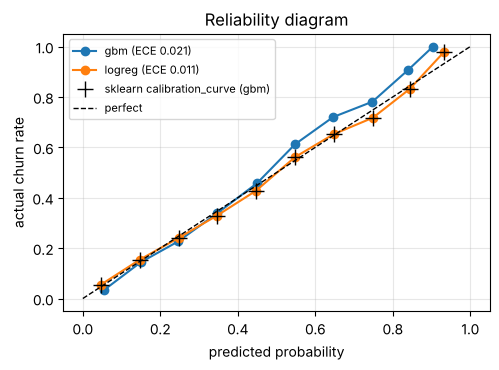

In [13]:
# 🔢 Reliability diagram by hand
def reliability_numpy(y_true, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); idx = np.clip(np.digitize(p, bins) - 1, 0, n_bins - 1)
    mean_p = np.array([p[idx == b].mean() for b in range(n_bins) if np.any(idx == b)])
    frac_pos = np.array([y_true[idx == b].mean() for b in range(n_bins) if np.any(idx == b)])
    counts = np.array([np.sum(idx == b) for b in range(n_bins) if np.any(idx == b)])
    ece = np.sum(counts / len(p) * np.abs(mean_p - frac_pos))       # expected calibration error
    return mean_p, frac_pos, ece

from sklearn.calibration import calibration_curve
for name, p in oof.items():
    mp, fp, ece = reliability_numpy(y_train, p)
    plt.plot(mp, fp, "o-", label=f"{name} (ECE {ece:.3f})")
frac, meanp = calibration_curve(y_train, p_oof, n_bins=10)
plt.plot(meanp, frac, "k+", ms=12, label="sklearn calibration_curve (gbm)")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
plt.xlabel("predicted probability"); plt.ylabel("actual churn rate"); plt.legend(fontsize=8); plt.title("Reliability diagram"); plt.show()

Both models are well calibrated (points near the diagonal; ECE ≈ average gap). If they weren't, wrap the model in `CalibratedClassifierCV` (Platt scaling or isotonic regression).

## 8. Choosing the decision threshold from business costs

The model outputs a probability *p*. We contact a customer when *p* ≥ threshold. Two ways to choose:

**(a) From the costs directly.** Contact if the expected gain is positive:
$$ p \cdot \$90 + (1-p)\cdot(-\$30) > 0 \;\;\Longleftrightarrow\;\; p > \frac{30}{90 + 30} = 0.25 $$
This only works if probabilities are calibrated — which we just checked.

**(b) Empirically:** sweep thresholds on the out-of-fold predictions and pick the one with the highest profit. Also handles **capacity limits** ("the team can only make 600 calls").

theoretical threshold 0.25 | empirical best 0.24 → profit $61,380 on the training customers
compare: rule 'contact month-to-month' made $48,180


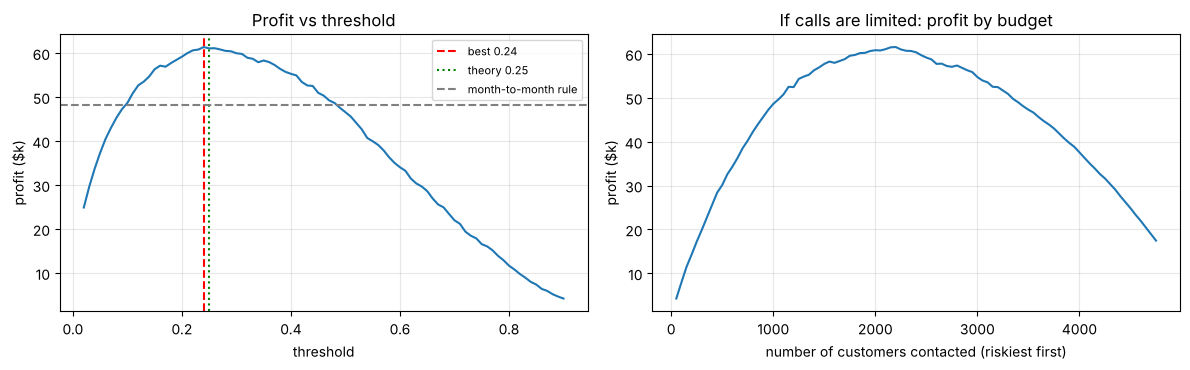

In [14]:
thresholds = np.linspace(0.02, 0.9, 89)
profits = np.array([profit(y_train, p_oof >= t) for t in thresholds])
best_t = thresholds[np.argmax(profits)]
theory_t = -COST_FP / (GAIN_TP - COST_FP)
print(f"theoretical threshold {theory_t:.2f} | empirical best {best_t:.2f} → profit ${profits.max():,.0f} on the training customers")
print(f"compare: rule 'contact month-to-month' made ${profit(y_train, rule):,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(thresholds, profits / 1000); ax[0].axvline(best_t, ls="--", c="r", label=f"best {best_t:.2f}")
ax[0].axvline(theory_t, ls=":", c="g", label=f"theory {theory_t:.2f}")
ax[0].axhline(profit(y_train, rule) / 1000, c="gray", ls="--", label="month-to-month rule")
ax[0].set_xlabel("threshold"); ax[0].set_ylabel("profit ($k)"); ax[0].legend(fontsize=8); ax[0].set_title("Profit vs threshold")

# Capacity-constrained: contact only the top-k riskiest customers
order = np.argsort(-p_oof); ks = np.arange(50, len(order), 50)
cum = [profit(y_train[order[:k]], np.ones(k)) for k in ks]
ax[1].plot(ks, np.array(cum) / 1000); ax[1].set_xlabel("number of customers contacted (riskiest first)")
ax[1].set_ylabel("profit ($k)"); ax[1].set_title("If calls are limited: profit by budget")
plt.tight_layout(); plt.show()

## 9. Final evaluation on the test set — once

Everything is decided: model, hyperparameters, threshold. Now refit on **all training data** and evaluate on the untouched test set. A **bootstrap confidence interval** shows how much the score could move with a different test sample.

In [15]:
final_model.fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
contact = p_test >= best_t

def bootstrap_ci_numpy(y_true, p, metric, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed); stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))            # resample test rows with replacement
        if len(np.unique(y_true[i])) == 2:
            stats.append(metric(y_true[i], p[i]))
    return np.percentile(stats, [2.5, 97.5])

lo, hi = bootstrap_ci_numpy(y_test, p_test, roc_auc_score)
print(f"TEST ROC-AUC {roc_auc_score(y_test, p_test):.4f}  (95% CI {lo:.3f}–{hi:.3f})   CV estimate was {study_lr.best_value:.4f}")
print(f"TEST PR-AUC  {average_precision_score(y_test, p_test):.4f}")
print(f"threshold {best_t:.2f}: contact {contact.sum()} of {len(y_test)} customers, "
      f"catching {np.sum(contact & (y_test == 1))} of {y_test.sum()} churners")
print(f"profit: model ${profit(y_test, contact):,.0f} | month-to-month rule ${profit(y_test, X_test['contract'] == 'month-to-month'):,.0f} | contact everyone ${profit(y_test, np.ones(len(y_test))):,.0f}")

TEST ROC-AUC 0.8324  (95% CI 0.809–0.857)   CV estimate was 0.8145
TEST PR-AUC  0.6634
threshold 0.24: contact 551 of 1200 customers, catching 277 of 334 churners
profit: model $16,710 | month-to-month rule $12,990 | contact everyone $4,080


The test score lands close to the cross-validation estimate — the sign of an honest process. (If test were *much* worse than CV, suspect leakage or a distribution shift between train and test.)

## 10. Save, reload, predict

Save the **whole pipeline** (preprocessing + model), not just the model — otherwise the production code must re-implement preprocessing exactly, and any mismatch causes **training-serving skew**. Save metadata alongside it.

In [16]:
import joblib, json, sklearn
from pathlib import Path
from churn_utils import clean, add_features

Path("models").mkdir(exist_ok=True)
joblib.dump(final_model, "models/churn_model.joblib")
meta = {"model": "LogisticRegression", "threshold": round(float(best_t), 3), "features": list(X.columns),
        "params": study_lr.best_params, "test_roc_auc": round(float(roc_auc_score(y_test, p_test)), 4),
        "sklearn_version": sklearn.__version__, "trained_rows": int(len(X_train))}
Path("models/churn_model.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "model": "LogisticRegression",
  "threshold": 0.24,
  "features": [
    "age",
    "region",
    "plan",
    "contract",
    "payment_method",
    "has_partner",
    "monthly_charges",
    "tenure_months",
    "total_charges",
    "support_calls",
    "avg_session_minutes",
    "satisfaction_score",
    "last_login_days_ago",
    "charges_per_month_of_tenure",
    "is_new_customer",
    "satisfaction_missing",
    "log_last_login"
  ],
  "params": {
    "C": 1.1446066488079247
  },
  "test_roc_auc": 0.8324,
  "sklearn_version": "1.9.1",
  "trained_rows": 4800
}


In [17]:
# Later, in another program: load and score a NEW customer given as raw fields
model = joblib.load("models/churn_model.joblib")
meta = json.loads(Path("models/churn_model.json").read_text())

def predict_churn(customer: dict) -> dict:
    """Raw customer record → churn probability and recommended action."""
    raw = pd.DataFrame([customer]).assign(churned=0, customer_id="new", cancellation_reason=None, signup_date="2025-01-01")
    features = add_features(clean(raw)).drop(columns="churned")[meta["features"]]   # SAME cleaning as training
    p = float(model.predict_proba(features)[0, 1])
    return {"churn_probability": round(p, 3), "contact": p >= meta["threshold"]}

new_customer = {"age": 29, "region": "North ", "plan": "premium", "contract": "month-to-month",
                "payment_method": "electronic check", "has_partner": "no", "monthly_charges": 99.0,
                "tenure_months": 3, "total_charges": "290.5", "support_calls": 4, "avg_session_minutes": 12.0,
                "satisfaction_score": None, "last_login_days_ago": 21}
loyal_customer = {**new_customer, "contract": "two-year", "tenure_months": 40, "total_charges": "3900",
                  "support_calls": 0, "satisfaction_score": 5, "last_login_days_ago": 1, "payment_method": "credit card"}
print("risky customer: ", predict_churn(new_customer))
print("loyal customer: ", predict_churn(loyal_customer))

risky customer:  {'churn_probability': 0.962, 'contact': True}
loyal customer:  {'churn_probability': 0.013, 'contact': False}


To serve this to other systems you'd wrap `predict_churn` in a small web API (e.g. FastAPI), or run it as a nightly **batch job** that scores every customer and writes a call list — batch is simpler and enough when decisions are made daily.

## 11. After launch: monitor and maintain

A model's performance decays as the world changes. Track:
- **Data quality:** missing rates, new category values, out-of-range numbers (the problems from notebook 08, but in production).
- **Input drift:** have feature distributions shifted from training? (e.g. a price change moves `monthly_charges`)
- **Prediction drift:** has the share of customers flagged changed sharply?
- **Outcome metrics (delayed):** once true churn is known, recompute AUC, calibration and **profit**.
- **Feedback loops:** customers we contact and save look like "non-churners" in future training data — keep a small random **holdout group** that isn't contacted, so you can measure the true uplift and retrain on unbiased data.

Retrain on a schedule or when monitoring flags a drop, and **A/B test** a new model against the current one before switching.

### A short model card
| | |
|---|---|
| **Purpose** | rank customers by churn risk for retention calls |
| **Data** | 6,000 customers, single snapshot; cleaning in `churn_utils.py` |
| **Model** | tuned logistic regression inside a preprocessing pipeline (impute, scale, one-hot) |
| **Performance** | see `models/churn_model.json`; profit beats the month-to-month rule |
| **Decision rule** | contact if p ≥ threshold, derived from $90 gain / $30 cost |
| **Limitations** | assumes the 40% save rate; snapshot data (no time split); not validated on new markets |

## Key takeaways
- Frame the problem in business terms first; let costs choose the metric and threshold.
- Lock the test set away; make every decision with cross-validation on training data.
- Always build baselines — a simple rule is a real competitor.
- Tune with random search or Optuna on log scales; prefer the simpler model when scores are within noise.
- Check calibration before multiplying probabilities by dollars.
- Save the entire pipeline plus metadata; reuse the *same* cleaning code in production; monitor after launch.

## Exercises
1. Re-run the threshold analysis for the tuned **gradient boosting** model (`oof["gbm"]`). Does it make more or less money than logistic regression?
2. Suppose the save rate is only 20%. Recompute the theoretical threshold. How many customers are now worth contacting?
3. Add an XGBoost or LightGBM model to Section 5 (see notebook 11 for their APIs).
4. Simulate drift: increase `monthly_charges` in `X_test` by 15% and re-score. How do the predicted churn rate and the share of contacted customers change?

In [18]:
# Exercise 2 — solution
gain_20 = 0.2 * 300 - 30
t20 = 30 / (gain_20 + 30)
print(f"save rate 20% → gain per saved churner ${gain_20:.0f} → contact if p > {t20:.2f}; "
      f"that's {np.sum(p_oof >= t20)} of {len(p_oof)} training customers (vs {np.sum(p_oof >= theory_t)} at 40%)")

save rate 20% → gain per saved churner $30 → contact if p > 0.50; that's 924 of 4800 training customers (vs 2128 at 40%)


In [19]:
# Exercise 4 — solution
X_drift = X_test.copy(); X_drift["monthly_charges"] *= 1.15
p_drift = final_model.predict_proba(X_drift)[:, 1]
print(f"mean predicted churn: {p_test.mean():.3f} → {p_drift.mean():.3f};  contacted: {np.mean(p_test >= best_t):.1%} → {np.mean(p_drift >= best_t):.1%}")
print("(note: total_charges and the engineered ratio weren't updated — in real drift, related features move together)")

mean predicted churn: 0.280 → 0.302;  contacted: 45.9% → 49.1%
(note: total_charges and the engineered ratio weren't updated — in real drift, related features move together)


**Next:** [10 · Explaining Models](10_explaining_models.ipynb) — *why* does the model think a customer will churn?

*Going deeper / interview prep:* `ML_System_Design_Notes.md` Part 0 (the 8-step framework), §5.2 (A/B testing), §5.4–5.7 (monitoring, retraining, thresholds & calibration, feedback loops), §2.4 (training-serving skew) · `ML_Interview_Notes.md` §2.4 (calibration) · `Probability_Statistics_Notes.md` §3.4 & §4.4 (bootstrap intervals).